
# LudFamily — Simulação de Deadlock

## Sistemas Operacionais — FATEC Mauá

### Objetivo

Demonstrar o funcionamento de mecanismos de prevenção,
evitação, detecção e recuperação de deadlocks por meio
de cenários fictícios relacionados à LudCommerce.

### Ferramentas utilizadas

- Python
- Google Colab
- NumPy
- NetworkX
- Matplotlib

### Contexto

A LudCommerce é uma loja fictícia de hardware e periféricos.
A simulação representa processos que disputam recursos
compartilhados, como conexões com banco de dados e acesso
ao estoque.

O laboratório utiliza dados fictícios e não representa
uma infraestrutura de produção.


## 1. Cenário de disputa por recursos

In [1]:

# SIMULAÇÃO DE DEADLOCK - LUCOMMERCE

# Processos existentes
processos = {
    "P1": "Processamento de pedidos",
    "P2": "Atualização de estoque"
}

# Recursos existentes
recursos = {
    "R1": "Conexão com banco de dados",
    "R2": "Acesso ao estoque"
}

# Recursos atualmente utilizados por cada processo
alocacao = {
    "P1": ["R1"],
    "P2": ["R2"]
}

# Recursos que cada processo ainda está aguardando
espera = {
    "P1": ["R2"],
    "P2": ["R1"]
}

print("=== CENÁRIO DA LUDCOMMERCE ===")

for processo, atividade in processos.items():
    print(f"\n{processo}: {atividade}")
    print(f"  Possui: {alocacao[processo]}")
    print(f"  Aguarda: {espera[processo]}")


=== CENÁRIO DA LUDCOMMERCE ===

P1: Processamento de pedidos
  Possui: ['R1']
  Aguarda: ['R2']

P2: Atualização de estoque
  Possui: ['R2']
  Aguarda: ['R1']


## 1.1. A espera circular

In [2]:

# IDENTIFICANDO A ESPERA CIRCULAR

for processo in processos:
    recurso_aguardado = espera[processo][0]

    # Descobre quem possui o recurso solicitado
    dono = None

    for outro_processo in alocacao:
        if recurso_aguardado in alocacao[outro_processo]:
            dono = outro_processo
            break

    print(f"{processo} aguarda {recurso_aguardado}, "
          f"que pertence a {dono}")


P1 aguarda R2, que pertence a P2
P2 aguarda R1, que pertence a P1


## 2. Grafo de alocação e espera

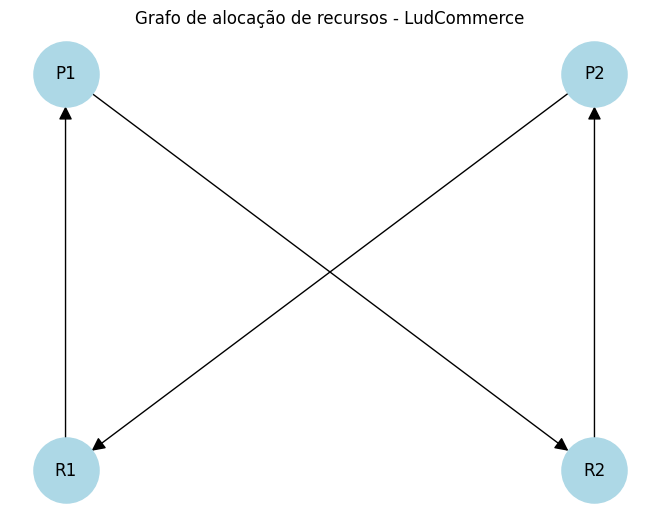

In [3]:

import networkx as nx
import matplotlib.pyplot as plt

# Criando o grafo
grafo = nx.DiGraph()

# Adicionando processos e recursos
grafo.add_nodes_from(["P1", "P2"], tipo="processo")
grafo.add_nodes_from(["R1", "R2"], tipo="recurso")

# Recursos alocados: recurso -> processo
grafo.add_edge("R1", "P1")
grafo.add_edge("R2", "P2")

# Recursos solicitados: processo -> recurso
grafo.add_edge("P1", "R2")
grafo.add_edge("P2", "R1")

# Posicionamento dos elementos
posicoes = {
    "P1": (0, 1),
    "P2": (2, 1),
    "R1": (0, 0),
    "R2": (2, 0)
}

# Desenhando o grafo
nx.draw(
    grafo,
    posicoes,
    with_labels=True,
    node_size=2200,
    node_color="lightblue",
    arrows=True,
    arrowsize=20,
    font_size=12
)

plt.title("Grafo de alocação de recursos - LudCommerce")
plt.axis("off")
plt.show()


## 3. Estruturas do algoritmo do banqueiro


In [4]:

import numpy as np

# Recursos disponíveis: A, B e C
available = np.array([3, 2, 2])

# Recursos já alocados para cada processo
allocation = np.array([
    [1, 0, 0],  # P0
    [0, 1, 1],  # P1
    [1, 1, 0]   # P2
])

# Necessidade máxima de cada processo
max_demand = np.array([
    [2, 1, 1],  # P0
    [1, 2, 2],  # P1
    [2, 1, 1]   # P2
])

# Calculando o que ainda falta para cada processo
need = max_demand - allocation

print("RECURSOS DISPONÍVEIS:")
print(available)

print("\nMATRIZ DE ALOCAÇÃO:")
print(allocation)

print("\nMATRIZ DE NECESSIDADE:")
print(need)


RECURSOS DISPONÍVEIS:
[3 2 2]

MATRIZ DE ALOCAÇÃO:
[[1 0 0]
 [0 1 1]
 [1 1 0]]

MATRIZ DE NECESSIDADE:
[[1 1 1]
 [1 1 1]
 [1 0 1]]


## 4. Verificação de estado seguro


In [5]:

def verificar_estado_seguro(available, allocation, need):

    # Cópia dos recursos disponíveis
    work = available.copy()

    # Controle dos processos que já terminaram
    finish = [False] * len(allocation)

    # Armazena a ordem de conclusão
    sequencia = []

    print("INICIANDO VERIFICAÇÃO DE SEGURANÇA\n")

    while len(sequencia) < len(allocation):

        encontrou = False

        for i in range(len(allocation)):

            # Verifica se o processo ainda não terminou
            # e se suas necessidades cabem nos recursos disponíveis
            if not finish[i] and np.all(need[i] <= work):

                print(f"P{i} pode terminar.")
                print(f"Recursos disponíveis antes: {work}")

                # Ao terminar, o processo libera seus recursos
                work += allocation[i]

                finish[i] = True
                sequencia.append(f"P{i}")

                print(f"Recursos disponíveis depois: {work}\n")

                encontrou = True
                break

        # Se nenhum processo puder terminar, não há sequência segura
        if not encontrou:
            print("Não foi encontrada uma sequência segura.")
            return False, sequencia

    print("ESTADO SEGURO!")
    print("Sequência segura:", " -> ".join(sequencia))

    return True, sequencia


# Executando o algoritmo
seguro, sequencia = verificar_estado_seguro(
    available,
    allocation,
    need
)


INICIANDO VERIFICAÇÃO DE SEGURANÇA

P0 pode terminar.
Recursos disponíveis antes: [3 2 2]
Recursos disponíveis depois: [4 2 2]

P1 pode terminar.
Recursos disponíveis antes: [4 2 2]
Recursos disponíveis depois: [4 3 3]

P2 pode terminar.
Recursos disponíveis antes: [4 3 3]
Recursos disponíveis depois: [5 4 3]

ESTADO SEGURO!
Sequência segura: P0 -> P1 -> P2


In [12]:

import numpy as np

# Recursos disponíveis: A e B
available = np.array([2, 0])

# Recursos já alocados
allocation = np.array([
    [0, 1],  # P0
    [1, 0]   # P1
])

# Necessidade máxima
max_demand = np.array([
    [2, 1],  # P0
    [2, 1]   # P1
])

# Necessidade restante
need = max_demand - allocation

print("Available:", available)
print("Allocation:\n", allocation)
print("Max:\n", max_demand)
print("Need:\n", need)


Available: [2 0]
Allocation:
 [[0 1]
 [1 0]]
Max:
 [[2 1]
 [2 1]]
Need:
 [[2 0]
 [1 1]]


## 5. Solicitação aprovada


In [14]:

def solicitar_recursos(processo, solicitacao):

    global available, allocation, need

    solicitacao = np.array(solicitacao)

    print(f"\nP{processo} solicita: {solicitacao}")

    # Verificação 1: respeita a necessidade restante?
    if np.any(solicitacao > need[processo]):
        print("NEGADA: excede a necessidade restante.")
        return

    # Verificação 2: existem recursos disponíveis?
    if np.any(solicitacao > available):
        print("NEGADA: recursos indisponíveis.")
        return

    # Simula a concessão
    available -= solicitacao
    allocation[processo] += solicitacao
    need[processo] -= solicitacao

    # Verificação 3: o estado continua seguro?
    seguro, sequencia = verificar_estado_seguro(
        available, allocation, need
    )

    if seguro:
        print("\nSOLICITAÇÃO APROVADA!")
        print("Sequência segura:", sequencia)
    else:
        # Desfaz a concessão
        available += solicitacao
        allocation[processo] -= solicitacao
        need[processo] += solicitacao

        print("\nSOLICITAÇÃO NEGADA!")
        print("A concessão deixaria o sistema inseguro.")
        print("Estado anterior restaurado.")

#Teste 1:

solicitar_recursos(0, [1, 0])



P0 solicita: [1 0]
INICIANDO VERIFICAÇÃO DE SEGURANÇA

P0 pode terminar.
Recursos disponíveis antes: [1 0]
Recursos disponíveis depois: [2 1]

P1 pode terminar.
Recursos disponíveis antes: [2 1]
Recursos disponíveis depois: [3 1]

ESTADO SEGURO!
Sequência segura: P0 -> P1

SOLICITAÇÃO APROVADA!
Sequência segura: ['P0', 'P1']


## 6. Solicitação negada


In [15]:

def solicitar_recursos(processo, solicitacao):

    global available, allocation, need

    solicitacao = np.array(solicitacao)

    print(f"\nP{processo} solicita: {solicitacao}")

    # Verificação 1: respeita a necessidade restante?
    if np.any(solicitacao > need[processo]):
        print("NEGADA: excede a necessidade restante.")
        return

    # Verificação 2: existem recursos disponíveis?
    if np.any(solicitacao > available):
        print("NEGADA: recursos indisponíveis.")
        return

    # Simula a concessão
    available -= solicitacao
    allocation[processo] += solicitacao
    need[processo] -= solicitacao

    # Verificação 3: o estado continua seguro?
    seguro, sequencia = verificar_estado_seguro(
        available, allocation, need
    )

    if seguro:
        print("\nSOLICITAÇÃO APROVADA!")
        print("Sequência segura:", sequencia)
    else:
        # Desfaz a concessão
        available += solicitacao
        allocation[processo] -= solicitacao
        need[processo] += solicitacao

        print("\nSOLICITAÇÃO NEGADA!")
        print("A concessão deixaria o sistema inseguro.")
        print("Estado anterior restaurado.")

#Teste 2:





P1 solicita: [1 0]
INICIANDO VERIFICAÇÃO DE SEGURANÇA

Não foi encontrada uma sequência segura.

SOLICITAÇÃO NEGADA!
A concessão deixaria o sistema inseguro.
Estado anterior restaurado.



## 7. Detecção de Deadlock

Nesta etapa, verificamos se existe uma espera circular
entre os processos da LudCommerce.

A detecção será realizada por meio da análise das
dependências entre processos e da identificação de ciclos.


In [16]:

# DETECÇÃO DE DEADLOCK

def detectar_deadlock(alocacao, espera):

    # Identifica quem está aguardando quem
    dependencias = {}

    for processo in espera:
        dependencias[processo] = []

        for recurso in espera[processo]:
            for outro_processo in alocacao:

                if recurso in alocacao[outro_processo]:
                    dependencias[processo].append(outro_processo)

    print("DEPENDÊNCIAS ENTRE PROCESSOS:")
    print(dependencias)

    # Procura ciclos nas dependências
    visitados = set()
    caminho = set()

    def encontrar_ciclo(processo):

        visitados.add(processo)
        caminho.add(processo)

        for vizinho in dependencias[processo]:

            if vizinho in caminho:
                return True

            if vizinho not in visitados:
                if encontrar_ciclo(vizinho):
                    return True

        caminho.remove(processo)
        return False

    for processo in dependencias:

        if processo not in visitados:
            if encontrar_ciclo(processo):
                print("\nDEADLOCK DETECTADO!")
                return True

    print("\nNenhum deadlock detectado.")
    return False


# Executando a detecção
detectar_deadlock(alocacao, espera)


DEPENDÊNCIAS ENTRE PROCESSOS:
{'P1': ['P2'], 'P2': ['P1']}

DEADLOCK DETECTADO!


True


## 8. Recuperação de Deadlock

Após identificar o impasse, simulamos a interrupção
do processo P2.

Os recursos mantidos por P2 são liberados, quebrando
a espera circular e permitindo que P1 continue.


In [17]:

# RECUPERAÇÃO DE DEADLOCK

print("=== INICIANDO RECUPERAÇÃO ===")

# Escolhemos interromper o processo P2
processo_interrompido = "P2"

# Identificamos os recursos que P2 possui
recursos_liberados = alocacao[processo_interrompido].copy()

# Interrompemos P2 e liberamos seus recursos
alocacao[processo_interrompido] = []

# Removemos a solicitação pendente de P2
espera[processo_interrompido] = []

# P1 deixa de aguardar R2
espera["P1"] = []

print("Processo interrompido:", processo_interrompido)
print("Recursos liberados:", recursos_liberados)

print("\nNova situação:")
print("Alocação:", alocacao)
print("Espera:", espera)

print("\nP1 não está mais aguardando R2.")
print("O impasse foi desfeito.")


=== INICIANDO RECUPERAÇÃO ===
Processo interrompido: P2
Recursos liberados: ['R2']

Nova situação:
Alocação: {'P1': ['R1'], 'P2': []}
Espera: {'P1': [], 'P2': []}

P1 não está mais aguardando R2.
O impasse foi desfeito.


In [18]:

print("=== NOVA VERIFICAÇÃO ===")

detectar_deadlock(alocacao, espera)


=== NOVA VERIFICAÇÃO ===
DEPENDÊNCIAS ENTRE PROCESSOS:
{'P1': [], 'P2': []}

Nenhum deadlock detectado.


False


## 9. Conclusão

A simulação demonstrou como processos podem entrar
em situação de deadlock ao disputar recursos compartilhados.

O grafo de alocação permitiu visualizar a espera circular
entre os processos P1 e P2.

O algoritmo do banqueiro demonstrou a análise de estados
seguros e inseguros, apresentando uma solicitação aprovada
e outra negada.

A etapa de detecção identificou o ciclo de dependências
entre os processos. Em seguida, a recuperação simulou a
interrupção de um processo e a liberação dos recursos,
desfazendo o impasse.

Concluímos que o gerenciamento adequado dos recursos é
fundamental para evitar interrupções e manter a continuidade
das operações em ambientes computacionais.
